# B12. Giải thích mô hình bằng SHAP

Giải thích LightGBM (mô hình chọn ở B11, `ml/models/LGBM.joblib`) trên toàn bộ tập kiểm tra (61.503 hồ sơ): toàn cục (yếu tố nào quan trọng, ảnh hưởng theo chiều nào) và từng hồ sơ (top-5 yếu tố làm tăng, top-5 làm giảm, đúng mẫu khoản 1 Điều 5 QĐ-26).
Không lựa chọn gì từ kết quả này: bước chỉ mô tả mô hình đã chốt, nên dùng tập kiểm tra không làm lạc quan kết quả nào.

## 0. Nguồn tra cứu và cái áp dụng

| Nguồn | Áp dụng | Không áp dụng |
|---|---|---|
| Lundberg, Lee (2017), *A Unified Approach to Interpreting Model Predictions*, NeurIPS | SHAP = giá trị Shapley: giá trị nền + tổng SHAP = đầu ra mô hình; tính nhất quán (consistency) mà độ quan trọng theo gain không có | – |
| Lundberg và cs. (2020), *From local explanations to global understanding with explainable AI for trees*, Nature Machine Intelligence 2, 56–67 | TreeSHAP tính chính xác trong thời gian đa thức; độ quan trọng toàn cục = trung bình \|SHAP\|; biểu đồ beeswarm, biểu đồ phụ thuộc | Giá trị tương tác SHAP (đề cương không yêu cầu) |
| Tài liệu `shap.TreeExplainer` (shap.readthedocs.io) | `feature_perturbation="tree_path_dependent"`: không cần dữ liệu nền, dùng số hồ sơ huấn luyện đi qua mỗi nhánh; `model_output="raw"` = log-odds; `check_additivity` | `model_output="probability"` chỉ có ở chế độ `interventional` (cần dữ liệu nền) |
| Tài liệu LightGBM `predict(pred_contrib=True)` | SHAP gốc của LightGBM, cột cuối là giá trị nền, thang log-odds; dùng để đối chiếu | – |
| Chen, Janizek, Lundberg, Lee (2020), *True to the model or true to the data?* | Hai cách định nghĩa "bỏ một yếu tố"; tree_path_dependent gần với cách theo dữ liệu (có điều kiện theo nhánh cây); lựa chọn tùy mục đích | Không tính cả hai cách để so (ngoài phạm vi) |
| Nghiên cứu SHAP trong chấm điểm tín dụng (arXiv 2509.11389; 2508.01851) | Yếu tố tương quan mạnh có thể chia nhau hoặc ngược dấu SHAP → kiểm tra tương quan giữa các yếu tố đứng đầu; thứ hạng các yếu tố tầm trung kém ổn định | Gom yếu tố thành "mã lý do" (QĐ-26 hiển thị từng yếu tố) |

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.stats import spearmanr

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA, FIG_DIR = ROOT / "ml" / "data", ROOT / "ml" / "hinh"
INK, MUTED, BLUE, ORANGE, GRID = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#e4e3df"
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

f = pd.read_parquet(DATA / "features.parquet").merge(pd.read_csv(DATA / "split.csv"), on="SK_ID_CURR")
tr, te = f[f.tap == "train"], f[f.tap == "test"]
X_te = te.drop(columns=["SK_ID_CURR", "TARGET", "tap"])
du_doan = pd.read_parquet(DATA / "du_doan_test.parquet")
hieu_chinh = json.loads((DATA / "hieu_chinh.json").read_text())
assert (du_doan.SK_ID_CURR.to_numpy() == te.SK_ID_CURR.to_numpy()).all()

pipe = joblib.load(ROOT / "ml" / "models" / "LGBM.joblib")
t, m = pipe[0], pipe[-1]
Xp = t.transform(X_te)
CHU = X_te.select_dtypes(exclude="number").columns.tolist()
print(f"Test {len(Xp):,} hồ sơ, {Xp.shape[1]} đặc trưng ({len(CHU)} cột chữ mã số nguyên), {m.booster_.num_trees()} cây; hiệu chỉnh LGBM: {hieu_chinh['LGBM']['cach']}")

Test 61,503 hồ sơ, 124 đặc trưng (15 cột chữ mã số nguyên), 971 cây; hiệu chỉnh LGBM: khong


## 1. Tính SHAP và kiểm tra cộng dồn

TreeSHAP chế độ `tree_path_dependent`, thang log-odds (đầu ra thô của cây). Kiểm tra ba điều:
(a) khớp SHAP gốc của LightGBM; (b) giá trị nền + tổng SHAP = log-odds thô; (c) sigmoid(log-odds thô) = xác suất đã lưu ở B11.
LightGBM không hiệu chỉnh (B9) nên (c) đúng; với mô hình có hiệu chỉnh thì tổng SHAP chỉ cộng ra xác suất trước hiệu chỉnh.

In [2]:
ex = shap.TreeExplainer(m, feature_perturbation="tree_path_dependent", model_output="raw")
S = np.asarray(ex.shap_values(Xp, check_additivity=True))
S = S[1] if S.ndim == 3 else S
nen = float(np.ravel(ex.expected_value)[-1])

goc = m.booster_.predict(Xp, pred_contrib=True)
tho = m.booster_.predict(Xp, raw_score=True)
p = 1 / (1 + np.exp(-tho))
print("(a) lệch lớn nhất so với pred_contrib:", np.abs(S - goc[:, :-1]).max(), "| nền:", nen, goc[0, -1])
print("(b) lệch lớn nhất nền + tổng SHAP − log-odds:", np.abs(nen + S.sum(1) - tho).max())
print("(c) lệch lớn nhất sigmoid(log-odds) − xác suất B11:", np.abs(p - du_doan.LGBM_hc).max())
print(f"Giá trị nền {nen:.4f} log-odds = {1 / (1 + np.exp(-nen)):.2%}; xác suất TB test {p.mean():.2%}; tỷ lệ thật {te.TARGET.mean():.2%}")

/home/tai/miniconda3/envs/credit-ai/lib/python3.11/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


(a) lệch lớn nhất so với pred_contrib: 0.0 | nền: -2.929359250498041 -2.929359250498041
(b) lệch lớn nhất nền + tổng SHAP − log-odds: 2.930988785010413e-14
(c) lệch lớn nhất sigmoid(log-odds) − xác suất B11: 1.1102230246251565e-16
Giá trị nền -2.9294 log-odds = 5.07%; xác suất TB test 7.95%; tỷ lệ thật 8.07%


## 2. Độ quan trọng toàn cục

Trung bình \|SHAP\| trên tập kiểm tra, đơn vị log-odds. So với độ quan trọng theo gain của LightGBM (tổng mức giảm hàm mất mát tại các lần chia), loại độ quan trọng không có tính nhất quán.
Nhóm theo bảng nguồn như notebook 06.

In [3]:
def nhom(c):
    for tien_to, ten in [("CICT_", "CIC theo tháng"), ("CIC_", "CIC"), ("AT_", "Hồ sơ cũ tại AT Credit"), ("KY_", "Kỳ trả nợ"),
                         ("TG_", "Khoản trả góp cũ theo tháng"), ("HM_", "Khoản AT Flex cũ theo tháng")]:
        if c.startswith(tien_to):
            return ten
    return "Hồ sơ"


tb_abs = pd.Series(np.abs(S).mean(0), index=Xp.columns)
gain = pd.Series(m.booster_.feature_importance("gain"), index=Xp.columns)
qt = pd.DataFrame({"TB |SHAP|": tb_abs, "tỷ trọng": tb_abs / tb_abs.sum(), "hạng SHAP": tb_abs.rank(ascending=False).astype(int),
                   "hạng gain": gain.rank(ascending=False).astype(int), "nhóm": [nhom(c) for c in Xp.columns]}).sort_values("hạng SHAP")
print(f"Spearman giữa hạng SHAP và hạng gain (124 đặc trưng): {spearmanr(tb_abs, gain)[0]:.3f}; "
      f"top-20 chung: {len(set(qt.index[:20]) & set(gain.nlargest(20).index))}/20")
print(f"Top-10 chiếm {qt['tỷ trọng'][:10].sum():.1%}, top-20 {qt['tỷ trọng'][:20].sum():.1%} tổng TB |SHAP|; "
      f"{(qt['tỷ trọng'] < 0.001).sum()} đặc trưng < 0,1%; {(tb_abs == 0).sum()} đặc trưng không được cây nào dùng")
qt.head(25)

Spearman giữa hạng SHAP và hạng gain (124 đặc trưng): 0.948; top-20 chung: 13/20
Top-10 chiếm 40.8%, top-20 60.8% tổng TB |SHAP|; 38 đặc trưng < 0,1%; 5 đặc trưng không được cây nào dùng


,TB |SHAP|,tỷ trọng,hạng SHAP,hạng gain,nhóm
EXT_SOURCE_2,0.2873,0.0848,1,2,Hồ sơ
EXT_SOURCE_3,0.2363,0.0698,2,1,Hồ sơ
EXT_SOURCE_1,0.1696,0.0501,3,3,Hồ sơ
VAY_TRA_KY,0.1181,0.0349,4,4,Hồ sơ
VAY_GIA_HANG,0.1084,0.0320,5,8,Hồ sơ
KY_SO_KY,0.1034,0.0305,6,12,Kỳ trả nợ
KY_MAX_NGAY_QH_12_THANG,0.0963,0.0284,7,13,Kỳ trả nợ
THAM_NIEN_THANG,0.0949,0.0280,8,6,Hồ sơ
ORGANIZATION_TYPE,0.0863,0.0255,9,5,Hồ sơ
AT_KY_HAN_TB,0.0818,0.0241,10,17,Hồ sơ cũ tại AT Credit


In [4]:
theo_nhom = qt.groupby("nhóm").agg(so_dac_trung=("TB |SHAP|", "size"), tong_TB_abs=("TB |SHAP|", "sum"), ty_trong=("tỷ trọng", "sum"),
                                     trong_top_20=("hạng SHAP", lambda h: (h <= 20).sum())).sort_values("tong_TB_abs", ascending=False)
theo_nhom

,so_dac_trung,tong_TB_abs,ty_trong,trong_top_20
nhóm,,,,
Hồ sơ,79,2.1914,0.6470,13
CIC,12,0.3948,0.1165,2
Kỳ trả nợ,9,0.3550,0.1048,3
Hồ sơ cũ tại AT Credit,9,0.2327,0.0687,1
Khoản AT Flex cũ theo tháng,6,0.0972,0.0287,0
Khoản trả góp cũ theo tháng,4,0.0842,0.0249,1
CIC theo tháng,5,0.0319,0.0094,0


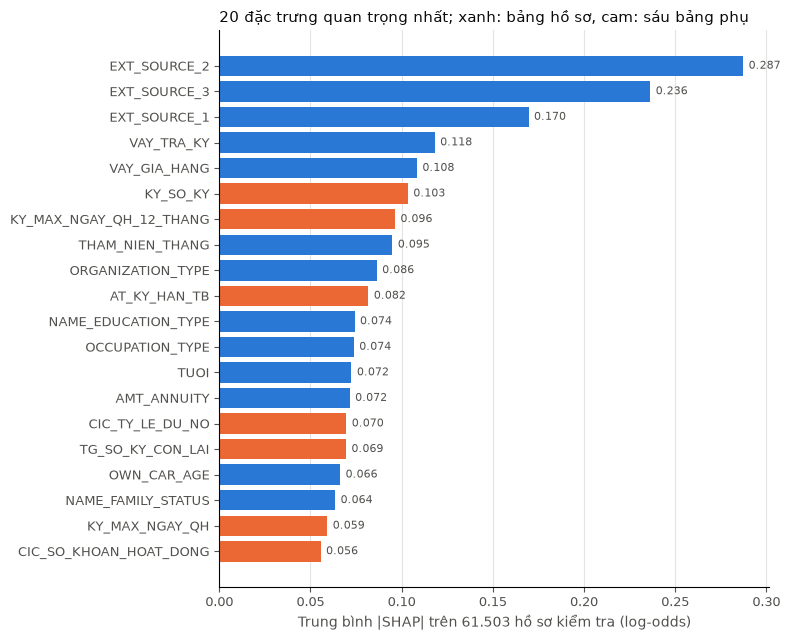

In [5]:
top = qt.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
mau = [ORANGE if n != "Hồ sơ" else BLUE for n in top["nhóm"]]
ax.barh(top.index, top["TB |SHAP|"], color=mau)
for i, v in enumerate(top["TB |SHAP|"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("Trung bình |SHAP| trên 61.503 hồ sơ kiểm tra (log-odds)", color=MUTED)
ax.set_title("20 đặc trưng quan trọng nhất; xanh: bảng hồ sơ, cam: sáu bảng phụ", color=INK, fontsize=11, loc="left")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, labelsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_shap_toan_cuc.png", dpi=150)

## 3. Chiều ảnh hưởng (beeswarm)

Mỗi chấm một hồ sơ: vị trí ngang là SHAP, màu là giá trị đặc trưng (đỏ cao, xanh thấp, xám = trống hoặc cột chữ, vì mã số của cột chữ không có thứ tự).

/home/tai/miniconda3/envs/credit-ai/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


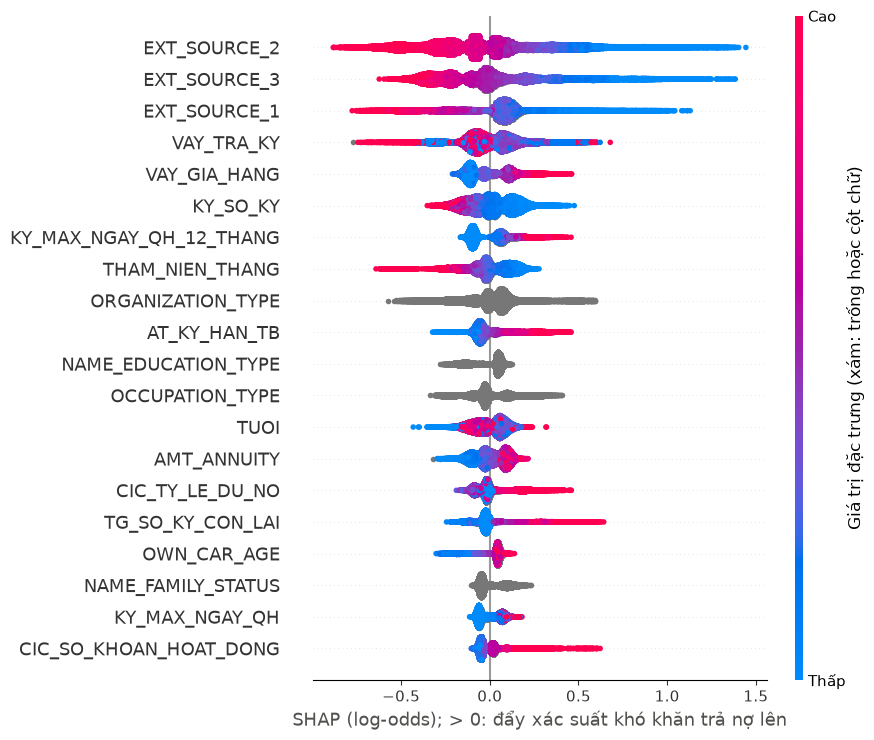

In [6]:
mau_gt = Xp.astype(float).copy()
mau_gt[CHU] = np.nan
shap.summary_plot(S, mau_gt, max_display=20, show=False, plot_size=(9, 7.5), rng=np.random.default_rng(42))
fig = plt.gcf()
fig.axes[0].set_xlabel("SHAP (log-odds); > 0: đẩy xác suất khó khăn trả nợ lên", color=MUTED)
fig.axes[1].set_ylabel("Giá trị đặc trưng (xám: trống hoặc cột chữ)")
fig.axes[1].set_yticklabels(["Thấp", "Cao"])
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_shap_beeswarm.png", dpi=150)

## 4. Quan hệ giá trị – SHAP của bốn đặc trưng chọn trước từ EDA

Chọn trước khi tính SHAP, theo kết quả EDA (notebook 05): `EXT_SOURCE_3` (IV lớn nhất), `VAY_TRA_KY` (IV 0,142, quan hệ răng cưa), `PTI` (khái niệm chính sách, IV gần 0),
`KY_THANG_TU_QH_10_GAN_NHAT` (mục 5.9: quá hạn càng xa ngày nộp càng ít rủi ro). Ô trống vẽ riêng bên phải mỗi hình.

,số trống,SHAP TB khi trống,SHAP TB khi có,TB |SHAP|,hạng
đặc trưng,,,,,
EXT_SOURCE_3,12160,-0.0138,-0.0012,0.2363,2
VAY_TRA_KY,2,-0.7493,0.0002,0.1181,4
PTI,2,-0.1282,0.0005,0.0501,23
KY_THANG_TU_QH_10_GAN_NHAT,47703,-0.0135,0.0489,0.0366,31


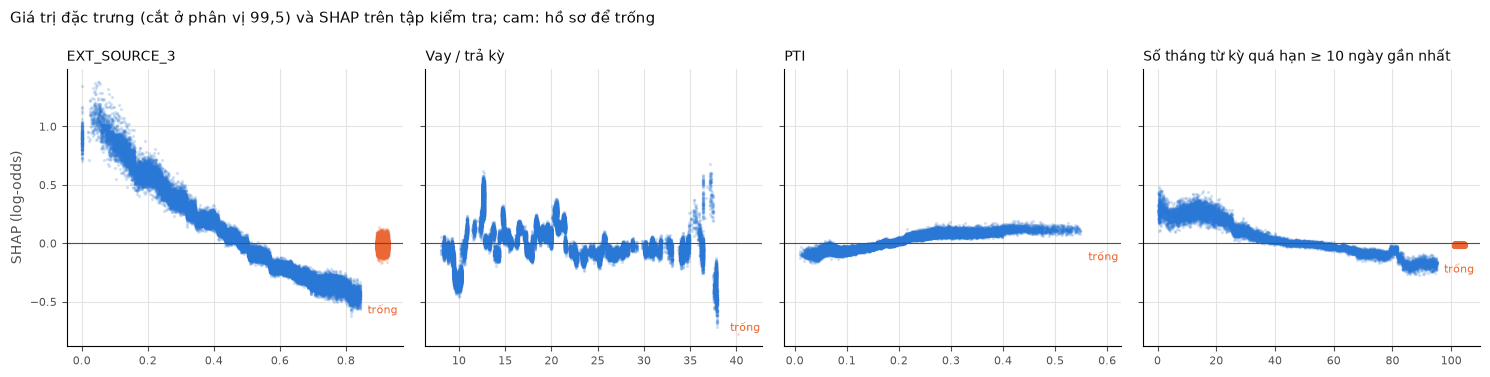

In [7]:
BON = ["EXT_SOURCE_3", "VAY_TRA_KY", "PTI", "KY_THANG_TU_QH_10_GAN_NHAT"]
NHAN = {"EXT_SOURCE_3": "EXT_SOURCE_3", "VAY_TRA_KY": "Vay / trả kỳ", "PTI": "PTI", "KY_THANG_TU_QH_10_GAN_NHAT": "Số tháng từ kỳ quá hạn ≥ 10 ngày gần nhất"}
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
rng = np.random.default_rng(42)
bang_thieu = []
for a, c in zip(ax, BON):
    j = Xp.columns.get_loc(c)
    x, s = Xp[c].to_numpy(float), S[:, j]
    co = ~np.isnan(x)
    hi = np.nanpercentile(x, 99.5)
    k = co & (x <= hi)
    a.scatter(x[k], s[k], s=2, alpha=0.15, color=BLUE, rasterized=True)
    if (~co).any():
        xm = hi * 1.08 + rng.uniform(-hi * 0.02, hi * 0.02, (~co).sum())
        a.scatter(xm, s[~co], s=2, alpha=0.15, color=ORANGE, rasterized=True)
        a.text(hi * 1.08, a.get_ylim()[0] if False else s.min(), "trống", color=ORANGE, fontsize=8, ha="center", va="bottom")
    a.axhline(0, color=MUTED, lw=0.8)
    a.set_title(NHAN[c], color=INK, fontsize=10, loc="left")
    a.grid(color=GRID, lw=0.8)
    a.set_axisbelow(True)
    a.tick_params(colors=MUTED, labelsize=8)
    a.spines[["top", "right"]].set_visible(False)
    bang_thieu.append({"đặc trưng": c, "số trống": (~co).sum(), "SHAP TB khi trống": s[~co].mean() if (~co).any() else np.nan,
                       "SHAP TB khi có": s[co].mean(), "TB |SHAP|": np.abs(s).mean(), "hạng": qt.loc[c, "hạng SHAP"]})
ax[0].set_ylabel("SHAP (log-odds)", color=MUTED)
fig.suptitle("Giá trị đặc trưng (cắt ở phân vị 99,5) và SHAP trên tập kiểm tra; cam: hồ sơ để trống", color=INK, fontsize=11, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_shap_phu_thuoc.png", dpi=150)
pd.DataFrame(bang_thieu).set_index("đặc trưng")

In [8]:
# chiều ảnh hưởng theo bậc của bốn đặc trưng: SHAP TB theo nhóm giá trị (5 nhóm cùng số hồ sơ)
for c in BON:
    x = Xp[c]
    g = pd.qcut(x, 5, duplicates="drop")
    print(c, pd.Series(S[:, Xp.columns.get_loc(c)], index=x.index).groupby(g, observed=True).mean().round(3).to_dict())

EXT_SOURCE_3 {Interval(-0.000473, 0.328, closed='right'): 0.563, Interval(0.328, 0.474, closed='right'): 0.15, Interval(0.474, 0.592, closed='right'): -0.105, Interval(0.592, 0.694, closed='right'): -0.25, Interval(0.694, 0.883, closed='right'): -0.368}
VAY_TRA_KY {Interval(8.036000000000001, 14.368, closed='right'): -0.027, Interval(14.368, 19.528, closed='right'): 0.069, Interval(19.528, 21.58, closed='right'): 0.117, Interval(21.58, 30.138, closed='right'): -0.083, Interval(30.138, 45.302, closed='right'): -0.075}
PTI {Interval(0.008480000000000001, 0.104, closed='right'): -0.063, Interval(0.104, 0.144, closed='right'): -0.044, Interval(0.144, 0.186, closed='right'): -0.014, Interval(0.186, 0.247, closed='right'): 0.035, Interval(0.247, 1.876, closed='right'): 0.089}
KY_THANG_TU_QH_10_GAN_NHAT {Interval(0.328, 18.2, closed='right'): 0.265, Interval(18.2, 35.578, closed='right'): 0.135, Interval(35.578, 53.548, closed='right'): 0.01, Interval(53.548, 70.506, closed='right'): -0.041, 

## 5. Chiều ảnh hưởng của các đặc trưng chính sách

Đối chiếu dấu SHAP trung bình với chiều mà văn bản AT Credit giả định (dấu hiệu rủi ro → đẩy điểm lên). Chỉ mô tả, không sửa mô hình theo kết quả.

In [9]:
X_g = X_te.reset_index(drop=True)
y, tong = te.TARGET.to_numpy(), S.sum(1)
CS = {"PTI > 40%": X_g.PTI > 0.4, "DTI > 60%": X_g.DTI > 0.6, "AT_QUA_HAN_HIEN_TAI ≥ 10 ngày": X_g.AT_QUA_HAN_HIEN_TAI >= 10,
      "AT_TU_CHOI_30_NGAY = 1": X_g.AT_TU_CHOI_30_NGAY == 1, "NHOM_NO_KHACH ≥ 2": X_g.NHOM_NO_KHACH >= 2,
      "THAM_NIEN_THANG < 6": X_g.THAM_NIEN_THANG < 6}
COT = {"PTI > 40%": "PTI", "DTI > 60%": "DTI", "AT_QUA_HAN_HIEN_TAI ≥ 10 ngày": "AT_QUA_HAN_HIEN_TAI", "AT_TU_CHOI_30_NGAY = 1": "AT_TU_CHOI_30_NGAY",
       "NHOM_NO_KHACH ≥ 2": "NHOM_NO_KHACH", "THAM_NIEN_THANG < 6": "THAM_NIEN_THANG"}
cs = []
for ten, mask in CS.items():
    s = S[:, Xp.columns.get_loc(COT[ten])]
    mask = mask.to_numpy()
    cs.append({"dấu hiệu": ten, "số hồ sơ": mask.sum(), "tỷ lệ thật khi có": y[mask].mean(), "khi không": y[~mask].mean(),
               "SHAP cột TB khi có": s[mask].mean(), "tỷ lệ SHAP cột > 0 khi có": (s[mask] > 0).mean(),
               "tổng SHAP hồ sơ TB khi có": tong[mask].mean(), "khi không ": tong[~mask].mean(), "hạng SHAP của cột": qt.loc[COT[ten], "hạng SHAP"]})
pd.DataFrame(cs).set_index("dấu hiệu")

,số hồ sơ,tỷ lệ thật khi có,khi không,SHAP cột TB khi có,tỷ lệ SHAP cột > 0 khi có,tổng SHAP hồ sơ TB khi có,khi không,hạng SHAP của cột
dấu hiệu,,,,,,,,
PTI > 40%,1579,0.0779,0.0808,0.1198,1.0000,0.0175,-0.0041,23
DTI > 60%,3234,0.0860,0.0804,0.0043,0.5142,0.1380,-0.0114,59
AT_QUA_HAN_HIEN_TAI ≥ 10 ngày,250,0.1440,0.0805,-0.0182,0.0080,0.5961,-0.0059,108
AT_TU_CHOI_30_NGAY = 1,730,0.1205,0.0802,-0.0069,0.0000,0.4376,-0.0088,118
NHOM_NO_KHACH ≥ 2,842,0.1627,0.0796,0.0092,0.6698,0.7225,-0.0136,109
THAM_NIEN_THANG < 6,1986,0.1062,0.0799,0.1644,1.0000,0.3803,-0.0163,8


In [10]:
# ba dấu hiệu có rủi ro thật cao nhưng SHAP của chính cột gần 0: cột nào mang phần tăng
for ten in ["AT_QUA_HAN_HIEN_TAI ≥ 10 ngày", "AT_TU_CHOI_30_NGAY = 1", "NHOM_NO_KHACH ≥ 2"]:
    mask = CS[ten].to_numpy()
    chenh = pd.Series(S[mask].mean(0) - S[~mask].mean(0), index=Xp.columns).nlargest(4)
    print(ten, "| tổng chênh", f"{tong[mask].mean() - tong[~mask].mean():+.3f}", "|", ", ".join(f"{c} {v:+.3f}" for c, v in chenh.items()))

AT_QUA_HAN_HIEN_TAI ≥ 10 ngày | tổng chênh +0.602 | KY_THANG_TU_QH_10_GAN_NHAT +0.143, KY_MAX_NGAY_QH_12_THANG +0.141, KY_MAX_NGAY_QH +0.093, KY_TY_LE_DA_TRA +0.070
AT_TU_CHOI_30_NGAY = 1 | tổng chênh +0.446 | EXT_SOURCE_3 +0.142, AT_THANG_TU_TU_CHOI_GAN_NHAT +0.098, AT_TY_LE_TU_CHOI +0.050, HM_TY_LE_SU_DUNG_HIEN_TAI +0.033
NHOM_NO_KHACH ≥ 2 | tổng chênh +0.736 | EXT_SOURCE_3 +0.310, KY_MAX_NGAY_QH_12_THANG +0.056, CIC_QUA_HAN_HIEN_TAI +0.045, KY_THANG_TU_QH_10_GAN_NHAT +0.045


## 6. Tương quan giữa các đặc trưng đứng đầu

B6 đã loại các cặp Spearman ≥ 0,9. Các cặp 0,7 – 0,9 trong top-20 vẫn có thể chia nhau SHAP. Tương quan tính trên tập huấn luyện.

In [11]:
t20 = qt.index[:20]
so = [c for c in t20 if c not in CHU]
r = tr[so].corr(method="spearman")
cap = [(a, b, r.loc[a, b]) for i, a in enumerate(so) for b in so[i + 1:] if abs(r.loc[a, b]) >= 0.7]
print(f"Top-20 (cột số): {len(cap)} cặp |Spearman| ≥ 0,7; lớn nhất {r.where(~np.eye(len(so), dtype=bool)).abs().max().max():.3f}")
r_all = tr[[c for c in Xp.columns if c not in CHU]].corr(method="spearman")
pd.DataFrame([{"cột chính sách": c, "hạng SHAP": qt.loc[c, "hạng SHAP"], "cột tương quan mạnh nhất": r_all[c].drop(c).abs().idxmax(),
               "|Spearman|": r_all[c].drop(c).abs().max(), "hạng SHAP cột đó": qt.loc[r_all[c].drop(c).abs().idxmax(), "hạng SHAP"]}
              for c in dict.fromkeys(COT.values())]).set_index("cột chính sách")

Top-20 (cột số): 0 cặp |Spearman| ≥ 0,7; lớn nhất 0.601


,hạng SHAP,cột tương quan mạnh nhất,|Spearman|,hạng SHAP cột đó
cột chính sách,,,,
PTI,23,VAY_THU_NHAP,0.7946,50
DTI,59,PTI,0.6000,23
AT_QUA_HAN_HIEN_TAI,108,HM_THANG_TU_QH_10_GAN_NHAT,0.5464,117
AT_TU_CHOI_30_NGAY,118,AT_THANG_TU_TU_CHOI_GAN_NHAT,0.3304,27
NHOM_NO_KHACH,109,CIC_QUA_HAN_HIEN_TAI,0.8202,99
THAM_NIEN_THANG,8,TUOI,0.3070,13


## 7. Giải thích từng hồ sơ

Đúng mẫu khoản 1 Điều 5 QĐ-26: tối đa năm yếu tố làm tăng và năm yếu tố làm giảm, kèm giá trị trong hồ sơ. Ba hồ sơ ví dụ, mỗi dải một hồ sơ:
hồ sơ có xác suất gần trung vị của dải nhất (chọn theo quy tắc cố định, không xem SHAP trước). SHAP ở thang log-odds, không cộng ra xác suất hiển thị (khoản 2 Điều 5 QĐ-26).

In [12]:
def dai(q):
    d = np.round(q * 100, 1)
    return np.select([d < 5, d < 15], ["thấp", "trung bình"], "cao")


def giai_thich(i, k=5):
    s = pd.Series(S[i], index=Xp.columns)
    gt = X_te.iloc[i]
    tang, giam = s[s > 0].nlargest(k), s[s < 0].nsmallest(k)
    bang = pd.concat([pd.DataFrame({"chiều": "tăng", "SHAP": tang}), pd.DataFrame({"chiều": "giảm", "SHAP": giam})])
    bang["giá trị trong hồ sơ"] = [gt[c] for c in bang.index]
    return bang


q = du_doan.LGBM_hc.to_numpy()
d = dai(q)
vi_du = {ten: np.flatnonzero(d == ten)[np.argmin(np.abs(q[d == ten] - np.median(q[d == ten])))] for ten in ["thấp", "trung bình", "cao"]}
for ten, i in vi_du.items():
    tong10 = giai_thich(i).SHAP.sum()
    print(f"\nDải {ten}: SK_ID_CURR {te.SK_ID_CURR.iloc[i]}, xác suất {q[i]:.1%} | nền {nen:.3f} + tổng SHAP {S[i].sum():+.3f} = log-odds {tho[i]:.3f}"
          f" | 10 yếu tố hiển thị {tong10:+.3f}, 114 còn lại {S[i].sum() - tong10:+.3f}")
    display(giai_thich(i))


Dải thấp: SK_ID_CURR 172588, xác suất 2.5% | nền -2.929 + tổng SHAP -0.753 = log-odds -3.682 | 10 yếu tố hiển thị -0.618, 114 còn lại -0.135


,chiều,SHAP,giá trị trong hồ sơ
KY_NGAY_TRA_SOM_TB,tăng,0.0977,1.3000
EXT_SOURCE_2,tăng,0.0931,0.4852
REG_CITY_NOT_LIVE_CITY,tăng,0.0925,1
KY_MAX_NGAY_QH_12_THANG,tăng,0.0765,NaN
CIC_TIEN_QUA_HAN_LON_NHAT,tăng,0.0756,"15,875.2350"
EXT_SOURCE_1,giảm,-0.5175,0.7421
ORGANIZATION_TYPE,giảm,-0.2624,Security Ministries
CIC_TY_LE_DU_NO,giảm,-0.0981,0.1453
VAY_GIA_HANG,giảm,-0.0922,1.0000
AT_KY_HAN_TB,giảm,-0.0829,8.0000



Dải trung bình: SK_ID_CURR 292129, xác suất 7.9% | nền -2.929 + tổng SHAP +0.480 = log-odds -2.449 | 10 yếu tố hiển thị +0.330, 114 còn lại +0.150


,chiều,SHAP,giá trị trong hồ sơ
AT_KY_HAN_TB,tăng,0.2761,28.0000
DAYS_REGISTRATION,tăng,0.1194,-20.0000
VAY_GIA_HANG,tăng,0.1156,1.1980
KY_MAX_NGAY_QH,tăng,0.0974,25.0000
ORGANIZATION_TYPE,tăng,0.0820,Business Entity Type 3
KY_MAX_NGAY_QH_12_THANG,giảm,-0.0982,0.0000
EXT_SOURCE_2,giảm,-0.0782,0.5741
TUOI,giảm,-0.0680,53.4401
KY_SO_KY,giảm,-0.0656,45.0000
NAME_FAMILY_STATUS,giảm,-0.0505,Married



Dải cao: SK_ID_CURR 292498, xác suất 22.5% | nền -2.929 + tổng SHAP +1.690 = log-odds -1.240 | 10 yếu tố hiển thị +0.808, 114 còn lại +0.881


,chiều,SHAP,giá trị trong hồ sơ
VAY_GIA_HANG,tăng,0.3159,1.4224
EXT_SOURCE_2,tăng,0.2648,0.3759
OCCUPATION_TYPE,tăng,0.2539,Drivers
VAY_TRA_KY,tăng,0.1897,21.3574
EXT_SOURCE_1,tăng,0.1519,NaN
TUOI,giảm,-0.0987,26.5791
CIC_TIEN_QUA_HAN_LON_NHAT,giảm,-0.0963,0.0000
KY_SO_KY,giảm,-0.0810,34.0000
CIC_SO_KHOAN_HOAT_DONG,giảm,-0.0487,0.0000
NAME_INCOME_TYPE,giảm,-0.0432,Commercial associate


In [13]:
# vì sao SHAP không đọc thẳng thành điểm %: cùng +0,5 log-odds đổi xác suất khác nhau tùy điểm xuất phát
for xp in [0.02, 0.08, 0.30]:
    lo = np.log(xp / (1 - xp))
    print(f"từ {xp:.0%}: +0,5 log-odds → {1 / (1 + np.exp(-(lo + 0.5))):.1%} (tăng {1 / (1 + np.exp(-(lo + 0.5))) - xp:+.1%})")

từ 2%: +0,5 log-odds → 3.3% (tăng +1.3%)
từ 8%: +0,5 log-odds → 12.5% (tăng +4.5%)
từ 30%: +0,5 log-odds → 41.4% (tăng +11.4%)


In [14]:
# số yếu tố có SHAP > 0 và < 0 mỗi hồ sơ (top-5 có luôn đủ 5 không), và phần SHAP mà 10 yếu tố hiển thị chiếm
n_tang, n_giam = (S > 0).sum(1), (S < 0).sum(1)
abs_sorted = np.sort(np.abs(S), 1)[:, ::-1]
phu = np.sort(np.where(S > 0, S, 0), 1)[:, ::-1][:, :5].sum(1) + np.sort(np.where(S < 0, -S, 0), 1)[:, ::-1][:, :5].sum(1)
print(f"Số yếu tố tăng mỗi hồ sơ: min {n_tang.min()}, trung vị {np.median(n_tang):.0f}; giảm: min {n_giam.min()}, trung vị {np.median(n_giam):.0f}")
print(f"10 yếu tố hiển thị chiếm trung vị {np.median(phu / np.abs(S).sum(1)):.1%} tổng |SHAP| của hồ sơ (phân vị 10%: {np.percentile(phu / np.abs(S).sum(1), 10):.1%})")

Số yếu tố tăng mỗi hồ sơ: min 31, trung vị 57; giảm: min 30, trung vị 62


10 yếu tố hiển thị chiếm trung vị 50.6% tổng |SHAP| của hồ sơ (phân vị 10%: 43.7%)
